# 3. Over-the-air federated learning

In OTA-FL every round's model updates are aggregated with AirComp. The physical layer is the
same `Scenario` as before; `learning.train` adds datasets, partitioners, NumPy models and the
FedSGD/FedAvg loop. Each round draws fresh channels, schedules devices, maps update entries onto
sub-channels, and records the aggregation error next to accuracy. An `aggregation="ideal"` run
with the same seeds gives the error-free reference.

This notebook uses the built-in synthetic task, so nothing is downloaded. For MNIST, put
`mnist.npz` in a folder and pass `data_root=` (or set `AIRCOMPKIT_DATA`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aircompkit as ac

print("AirCompKit", ac.__version__)

AirCompKit 1.0.0


In [2]:
from aircompkit.core.scenario import load_yaml
from aircompkit.learning import FederatedConfig, train

cfg = load_yaml("../../configs/otafl_synthetic.yaml")   # the shipped example config
sc = ac.Scenario.from_dict(cfg)
# a harder synthetic task than the config's default, so that channel effects are visible
task = {"name": "synthetic", "dim": 40, "n_classes": 10, "separation": 1.0}
learning = {**cfg["learning"], "dataset": task, "rounds": 60, "eval_every": 5}
print(sc.to_dict()["power_control"])

{'name': 'truncated_inversion', 'threshold': 0.1, 'relative': True, 'budget': 'peak'}


In [3]:
ota = train(sc, FederatedConfig(**learning))
ideal = train(sc, FederatedConfig(**learning, aggregation="ideal"))
print("final accuracy  OTA %.4f   ideal %.4f" % (ota["test_acc"][-1], ideal["test_acc"][-1]))
print("arrays:", sorted(ota.arrays))

final accuracy  OTA 0.8040   ideal 0.8110
arrays: ['agg_nmse', 'channel_uses', 'eval_round', 'n_scheduled', 'test_acc', 'test_loss', 'train_loss']


## The effect of receiver noise

The config has 1 mW devices with -30 dB reference path loss at 10-100 m. Raising the noise power
pushes the cell edge into the noise-limited regime:

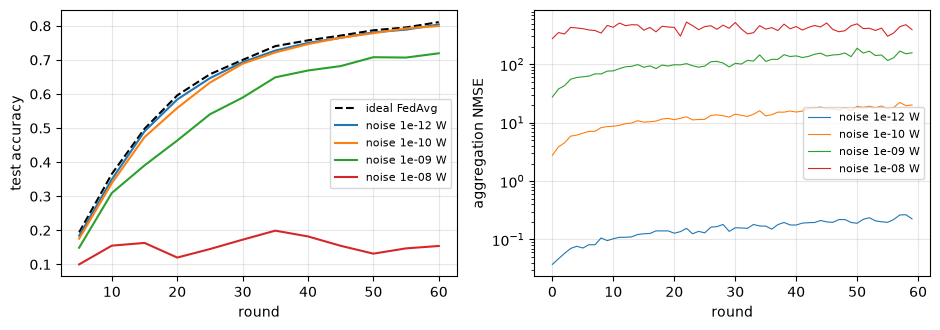

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(9.5, 3.4))
a.plot(ideal["eval_round"], ideal["test_acc"], "k--", label="ideal FedAvg")
for nv in (1e-12, 1e-10, 1e-9, 1e-8):
    r = train(sc.replace(noise_var=nv), FederatedConfig(**learning))
    a.plot(r["eval_round"], r["test_acc"], label=f"noise {nv:g} W")
    b.semilogy(r["agg_nmse"], lw=0.8, label=f"noise {nv:g} W")
a.set_xlabel("round"); a.set_ylabel("test accuracy"); a.legend(fontsize=8); a.grid(alpha=0.3)
b.set_xlabel("round"); b.set_ylabel("aggregation NMSE"); b.legend(fontsize=8); b.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Learning tolerates far more aggregation error than the NMSE suggests: zero-mean channel noise
averages out over SGD steps, much like gradient noise. Only when the noise dominates the update
(here at $10^{-8}$ W) does training fail.

## Data heterogeneity

Partitioners: `iid`, `shards` (each device gets a few label shards) and `dirichlet` (label
proportions $\sim \mathrm{Dir}(\alpha)$; small $\alpha$ means very non-IID).

In [5]:
for part in ("iid", {"name": "dirichlet", "alpha": 1.0}, {"name": "dirichlet", "alpha": 0.1},
             {"name": "shards", "shards_per_device": 1}):
    r = train(sc, FederatedConfig(**{**learning, "partition": part}))
    print(f"{str(part):45s} accuracy {r['test_acc'][-1]:.4f}")

iid                                           accuracy 0.8060


{'name': 'dirichlet', 'alpha': 1.0}           accuracy 0.8070


{'name': 'dirichlet', 'alpha': 0.1}           accuracy 0.7820


{'name': 'shards', 'shards_per_device': 1}    accuracy 0.7870


## Gradient bank: record once, replay over many channels

Training is the slow part. A `GradientBank` stores the updates of chosen rounds; `replay`
aggregates them again over fresh channel draws, which makes aggregation-error studies cheap.

In [6]:
from aircompkit.learning import GradientBank

bank = GradientBank()
train(sc, FederatedConfig(**{**learning, "record_bank": [5, 30, 55]}), bank=bank)
for rx in ("eigen", "maxmin"):
    rep = bank.replay(sc.replace(receiver=rx), trials=20, subchannels=8)
    print(f"{rx:7s} median NMSE per stored round:", np.round(np.median(rep["nmse"], axis=1), 5))

eigen   median NMSE per stored round: [0.07984 0.16077 0.24104]


maxmin  median NMSE per stored round: [0.0709  0.15254 0.21809]


From the command line: `aircompkit train configs/otafl_synthetic.yaml --out results/otafl`.
Next: [attacks and defences](04_attacks_and_defences.ipynb).